# Análisis de errores

Rúbrica D3: al menos 5 errores, agrupados por tipo, con hipótesis de causa.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import *
sns.set_theme(style="whitegrid")
FIG_DIR.mkdir(parents=True, exist_ok=True)
ARCH = DEFAULT_ARCH

In [2]:
from PIL import Image
pred = pd.read_csv(RUNS_DIR / ARCH / "eval_test" / "predictions.csv")
err = pred[pred.label != pred.pred].copy()
print(f"Errores: {len(err)} de {len(pred)} ({len(err)/len(pred):.1%})")
pairs = err.groupby(["label", "pred"]).size().sort_values(ascending=False).rename("n").reset_index()
pairs["real"] = pairs.label.map(DISPLAY); pairs["predicho"] = pairs.pred.map(DISPLAY)
pairs[["real", "predicho", "n"]].head(12)

Errores: 343 de 2374 (14.4%)


,real,predicho,n
0,Otro platillo,Tacos,23
1,Otro platillo,Huevos rancheros,17
2,Otro platillo,Ceviche,16
3,Burrito,Quesadilla,14
4,Huevos rancheros,Tacos,14
5,Burrito,Huevos rancheros,14
6,Huevos rancheros,Nachos,13
7,Nachos,Tacos,13
8,Ceviche,Otro platillo,12
9,Otro platillo,Churros,12


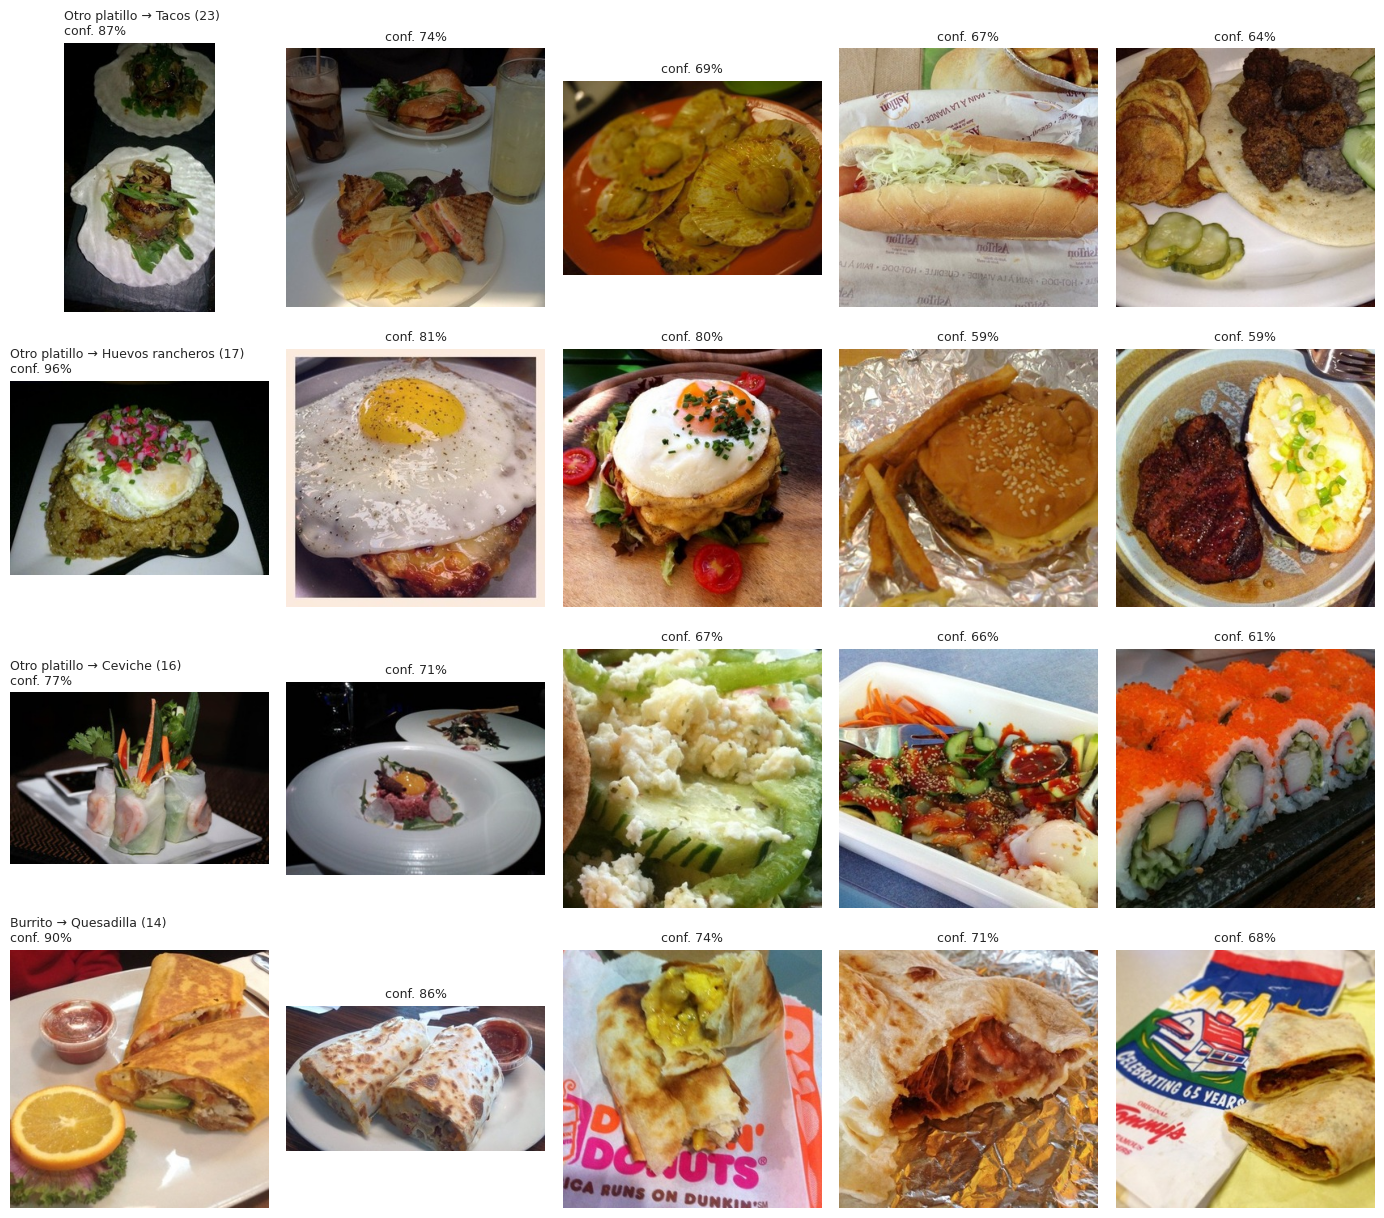

In [3]:
top_pairs = pairs.head(4)
fig, axes = plt.subplots(len(top_pairs), 5, figsize=(14, 3.1 * len(top_pairs)))
for i, r in enumerate(top_pairs.itertuples()):
    ex = err[(err.label == r.label) & (err.pred == r.pred)].sort_values("conf", ascending=False).head(5)
    for j in range(5):
        ax = axes[i, j]; ax.axis("off")
        if j < len(ex):
            e = ex.iloc[j]; ax.imshow(Image.open(ROOT / e.path)); ax.set_title((f"{r.real} → {r.predicho} ({r.n})\n" if j == 0 else "\n") + f"conf. {e.conf:.0%}", fontsize=9, loc="left" if j == 0 else "center")
plt.tight_layout(); plt.savefig(FIG_DIR / "analisis_errores.png", dpi=95); plt.show()

## Errores con confianza alta (los más peligrosos para el usuario)

In [4]:
hi = err[err.conf >= 0.8]
print(f"Errores con confianza ≥ 80%: {len(hi)} ({len(hi)/len(pred):.1%} del test)")
hi.assign(real=hi.label.map(DISPLAY), predicho=hi.pred.map(DISPLAY))[["real", "predicho", "conf"]].head(10)

Errores con confianza ≥ 80%: 31 (1.3% del test)


,real,predicho,conf
30,Burrito,Tacos,0.909292
42,Burrito,Huevos rancheros,0.912140
118,Burrito,Quesadilla,0.861681
134,Burrito,Quesadilla,0.895999
226,Burrito,Tacos,0.853061
265,Ceviche,Tacos,0.854076
270,Ceviche,Tacos,0.960758
478,Ceviche,Otro platillo,0.875259
559,Quesadilla,Nachos,0.880625
588,Quesadilla,Burrito,0.839543


Las hipótesis por tipo de error están documentadas en `docs/analisis_errores.md`.